## Week 11 _Deep Learning: Implementing RNN on the IMDB Dataset¶
#### Module 11- Sequence Modeling with Recurrent Networks





In [2]:
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
import matplotlib.pyplot as plt
import numpy as np

In [3]:
import tensorflow as tf
from tensorflow.keras.datasets import imdb

# Define our vocabulary size limit (keep only the top 10,000 frequent words)
vocab_size = 10000

print("1. Loading IMDB dataset...")
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=vocab_size)

print("\n--- Dataset Loaded Successfully ---")
print(f"Total training reviews: {len(x_train)}")
print(f"Total testing reviews: {len(x_test)}")

# Inspect a raw sample (stored as integers)
print("\n--- Inspecting Training Sample #0 (Encoded as Integers) ---")
print("First 20 word IDs:", x_train[0][:20])
print("Sentiment Label:", y_train[0], "(1 = Positive, 0 = Negative)")

# Decode the integer sequence back into readable text for students
word_index = imdb.get_word_index()
# Shift indices by 3 because 0=padding, 1=start of sequence, 2=unknown/out-of-vocabulary
reverse_word_index = {v + 3: k for k, v in word_index.items()}
reverse_word_index[0] = '<PAD>'
reverse_word_index[1] = '<START>'
reverse_word_index[2] = '<UNK>'

decoded_review = ' '.join([reverse_word_index.get(i, '?') for i in x_train[0][:40]])
print(f"\n--- Decoded Text Preview (First 40 words) ---\n{decoded_review}...")

1. Loading IMDB dataset...

--- Dataset Loaded Successfully ---
Total training reviews: 25000
Total testing reviews: 25000

--- Inspecting Training Sample #0 (Encoded as Integers) ---
First 20 word IDs: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
Sentiment Label: 1 (1 = Positive, 0 = Negative)

--- Decoded Text Preview (First 40 words) ---
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came...


## Step 2: Sequence Padding & Truncating
What we are doing here:
Neural networks require every input sample in a batch to have the exact same shape (length). However, real movie reviews vary wildly—some are 50 words, while others are 500 words.

We use pad_sequences to standardize them to a fixed length (e.g., max_length = 150 words):

Shorter reviews get filled with <PAD> zeros at the end (padding='post').

Longer reviews get cut off (truncated) at 150 words (truncating='post').

We will inspect the lengths before and after padding so students can clearly see the transformation.

In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Set maximum length for reviews
max_length = 150

print("2. Padding sequences to a uniform length of 150 words...")

# Inspect length of a couple of raw reviews BEFORE padding
print(f"Original length of review #0: {len(x_train[0])} words")
print(f"Original length of review #1: {len(x_train[1])} words")

# Apply padding
x_train_padded = pad_sequences(x_train, maxlen=max_length, padding='post', truncating='post')
x_test_padded = pad_sequences(x_test, maxlen=max_length, padding='post', truncating='post')

print("\n--- Sequences Padded Successfully ---")
print(f"Shape of x_train_padded: {x_train_padded.shape}")
print(f"Shape of x_test_padded:  {x_test_padded.shape}")

# Inspect padded length of sample #0
print(f"\nNew length of review #0: {len(x_train_padded[0])} integers")
print("First 20 word IDs of review #0 (padded):")
print(x_train_padded[0][:20])

2. Padding sequences to a uniform length of 150 words...
Original length of review #0: 218 words
Original length of review #1: 189 words

--- Sequences Padded Successfully ---
Shape of x_train_padded: (25000, 150)
Shape of x_test_padded:  (25000, 150)

New length of review #0: 150 integers
First 20 word IDs of review #0 (padded):
[   1   14   22   16   43  530  973 1622 1385   65  458 4468   66 3941
    4  173   36  256    5   25]


In [6]:
## Checking padding part
print("--- Verifying Padded Sample Lengths and Values ---")

# Check lengths of the first two samples
print(f"Length of padded training sample #0: {len(x_train_padded[0])}")
print(f"Length of padded training sample #1: {len(x_train_padded[1])}")

# Let's inspect the end of Sample #0 to see the padding (zeros)
# (Sample #0 was originally long, so let's look at the last 15 elements)
print("\nLast 15 word IDs of Sample #0 (showing tail):")
print(x_train_padded[0][-15:])

# Let's inspect a shorter sample that required padding zeros
# Find a review whose original length was less than 150
for i, orig_review in enumerate(x_train):
    if len(orig_review) < 150:
        print(f"\nFound a short review at index {i}:")
        print(f"  Original length: {len(orig_review)}")
        print(f"  Padded length:   {len(x_train_padded[i])}")
        print(f"  Last 20 IDs (showing <PAD> zeros at 'post'):")
        print(x_train_padded[i][-20:])
        break

--- Verifying Padded Sample Lengths and Values ---
Length of padded training sample #0: 150
Length of padded training sample #1: 150

Last 15 word IDs of Sample #0 (showing tail):
[ 107  117 5952   15  256    4    2    7 3766    5  723   36   71   43
  530]

Found a short review at index 2:
  Original length: 141
  Padded length:   150
  Last 20 IDs (showing <PAD> zeros at 'post'):
[  8 106 607 624  35 534   6 227   7 129 113   0   0   0   0   0   0   0
   0   0]


## Step 3: Building and Training the Vanilla SimpleRNN Model
We are constructing a sequential Keras model with three key layers:

Embedding: Transforms our integer word IDs into dense vector representations (our "learned word meanings").

SimpleRNN: The vanilla recurrent layer. It processes the sequence step-by-step, passing a hidden state (memory) from word to word.

Dense: A final output layer with a sigmoid activation to predict a probability between 0 (negative) and 1 (positive).

In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

# 1. Define hyperparameters
vocab_size = 10000
embedding_dim = 32
max_length = 150

print("Building SimpleRNN model...")
rnn_model = Sequential([
    # Step A: Turns integer sequences into dense vectors
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length),
    
    # Step B: The vanilla RNN layer (32 memory units)
    SimpleRNN(32, return_sequences=False),
    
    # Step C: Binary classification output layer (Positive / Negative)
    Dense(1, activation='sigmoid')
])

# 2. Compile the model
rnn_model.compile(
    loss='binary_crossentropy', 
    optimizer='adam', 
    metrics=['accuracy']
)

# Print model architecture summary
rnn_model.summary()

# 3. Train the model on our padded training data
print("\nTraining SimpleRNN model (this will take a couple of minutes)...")
history_rnn = rnn_model.fit(
    x_train_padded, 
    y_train, 
    batch_size=64, 
    epochs=10, 
    validation_split=0.2
)

Building SimpleRNN model...


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_1 (SimpleRNN)             │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Training SimpleRNN model (this will take a couple of minutes)...
Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.5104 - loss: 0.6939 - val_accuracy: 0.4940 - val_loss: 0.7090
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.6285 - loss: 0.6488 - val_accuracy: 0.5064 - val_loss: 0.7141
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.7652 - loss: 0.4680 - val_accuracy: 0.5090 - val_loss: 0.8202
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.8723 - loss: 0.2692 - val_accuracy: 0.5250 - val_loss: 0.9898
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.9209 - loss: 0.1735 - val_accuracy: 0.6170 - val_loss: 0.9359
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9363 - loss: 0.1508 - val_accuracy: 0.5468 - val_loss: 1.2888
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9416 - loss: 0.1451 - val_accuracy: 0.5118 - val_loss: 1.3123
Epoch 8/10
313/313 ━━━━━━━━━━━━

In [9]:
# Print model architecture summary
rnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ (None, 150, 32)             │         320,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_1 (SimpleRNN)             │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 966,341 (3.69 MB)

 Trainable params: 322,113 (1.23 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 644,228 (2.46 MB)

#### Evaluating the SimpleRNN on Test Samples


In [10]:
import numpy as np

print("--- Testing SimpleRNN on Unseen Test Data ---")

# Predict probabilities on the first 5 test reviews
test_preds_probs = rnn_model.predict(x_test_padded[:5])
test_preds = (test_preds_probs > 0.5).astype(int)

for i in range(5):
    print(f"Review #{i}: True Label = {y_test[i]} (1=Pos, 0=Neg) | Predicted Prob = {test_preds_probs[i][0]:.4f} | Predicted Class = {test_preds[i][0]}")

# Evaluate overall test accuracy across all 25,000 test reviews
test_loss, test_acc = rnn_model.evaluate(x_test_padded, y_test, verbose=0)
print(f"\nOverall SimpleRNN Test Accuracy on 25,000 test reviews: {test_acc * 100:.2f}%")

--- Testing SimpleRNN on Unseen Test Data ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step
Review #0: True Label = 0 (1=Pos, 0=Neg) | Predicted Prob = 0.5337 | Predicted Class = 1
Review #1: True Label = 1 (1=Pos, 0=Neg) | Predicted Prob = 0.5554 | Predicted Class = 1
Review #2: True Label = 1 (1=Pos, 0=Neg) | Predicted Prob = 0.9830 | Predicted Class = 1
Review #3: True Label = 0 (1=Pos, 0=Neg) | Predicted Prob = 0.0300 | Predicted Class = 0
Review #4: True Label = 1 (1=Pos, 0=Neg) | Predicted Prob = 0.0016 | Predicted Class = 0

Overall SimpleRNN Test Accuracy on 25,000 test reviews: 50.51%


In [13]:
print("--- Demonstrating RNN Step-by-Step Cumulative Input (Unrolling) ---")

# 1. Take a sample sentence (let's take the first 6 words of a test review)
sample_indices = x_test_padded[0][:6] 

# Decode them back to words for a clean human-readable demo
word_index = imdb.get_word_index()
reverse_word_index = {v + 3: k for k, v in word_index.items()}
reverse_word_index[0] = '<PAD>'
reverse_word_index[1] = '<START>'
reverse_word_index[2] = '<UNK>'

sample_words = [reverse_word_index.get(idx, '?') for idx in sample_indices]

print(f"Full target sequence to process: {sample_words}\n")
##print("How the RNN processes this sequentially across time steps (t):\n=" * 35)

# 2. Simulate the step-by-step accumulation (The RNN Time-Loop)
for t in range(1, len(sample_words) + 1):
    # Slice the sequence from the beginning up to the current time step t
    current_input_slice = sample_words[:t]
    
    print(f"Time Step t = {t}:")
    print(f"  --> Input fed to model: {current_input_slice}")
    print(f"  --> RNN combines this with the previous hidden state (h_{t-1}) to compute h_{t}\n")

--- Demonstrating RNN Step-by-Step Cumulative Input (Unrolling) ---
Full target sequence to process: ['<START>', 'please', 'give', 'this', 'one', 'a']

Time Step t = 1:
  --> Input fed to model: ['<START>']
  --> RNN combines this with the previous hidden state (h_0) to compute h_1

Time Step t = 2:
  --> Input fed to model: ['<START>', 'please']
  --> RNN combines this with the previous hidden state (h_1) to compute h_2

Time Step t = 3:
  --> Input fed to model: ['<START>', 'please', 'give']
  --> RNN combines this with the previous hidden state (h_2) to compute h_3

Time Step t = 4:
  --> Input fed to model: ['<START>', 'please', 'give', 'this']
  --> RNN combines this with the previous hidden state (h_3) to compute h_4

Time Step t = 5:
  --> Input fed to model: ['<START>', 'please', 'give', 'this', 'one']
  --> RNN combines this with the previous hidden state (h_4) to compute h_5

Time Step t = 6:
  --> Input fed to model: ['<START>', 'please', 'give', 'this', 'one', 'a']
  --> RN

--- SimpleRNN Confusion Matrix (All Test Cases) ---
True Negatives  (Correctly predicted Negative): 5871
False Positives (Predicted Positive, actually Neg): 6629
False Negatives (Predicted Negative, actually Pos): 5744
True Positives  (Correctly predicted Positive): 6756


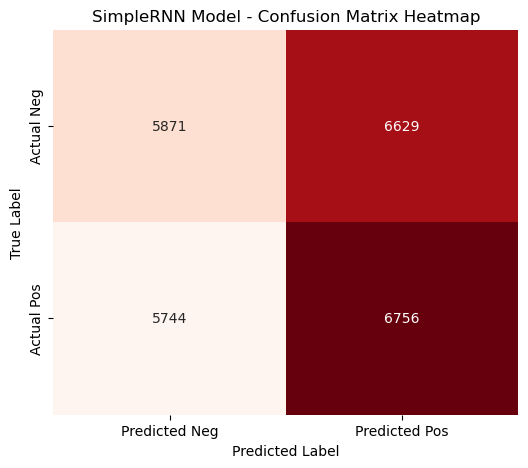

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("--- SimpleRNN Confusion Matrix (All Test Cases) ---")

# 1. Compute confusion matrix for SimpleRNN
cm_rnn = confusion_matrix(y_test, rnn_all_preds)

# 2. Print out the numerical breakdown
print("=" * 50)
print(f"True Negatives  (Correctly predicted Negative): {cm_rnn[0, 0]}")
print(f"False Positives (Predicted Positive, actually Neg): {cm_rnn[0, 1]}")
print(f"False Negatives (Predicted Negative, actually Pos): {cm_rnn[1, 0]}")
print(f"True Positives  (Correctly predicted Positive): {cm_rnn[1, 1]}")
print("=" * 50)

# 3. Plot the visual heatmap for classroom demonstration
plt.figure(figsize=(6, 5))
sns.heatmap(cm_rnn, annot=True, fmt='d', cmap='Reds', cbar=False,
            xticklabels=['Predicted Neg', 'Predicted Pos'],
            yticklabels=['Actual Neg', 'Actual Pos'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('SimpleRNN Model - Confusion Matrix Heatmap')
plt.show()

In [25]:
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score

print("--- SimpleRNN Detailed Classification Report ---")

# 1. Compute individual key metrics for SimpleRNN using rnn_all_preds
rnn_acc = accuracy_score(y_test, rnn_all_preds)
rnn_prec = precision_score(y_test, rnn_all_preds, zero_division=0)
rnn_rec = recall_score(y_test, rnn_all_preds, zero_division=0)
rnn_f1 = f1_score(y_test, rnn_all_preds, zero_division=0)

print("\n[1] Key Performance Metrics:")
print(f"  • Accuracy  : {rnn_acc * 100:.2f}%")
print(f"  • Precision : {rnn_prec:.4f}")
print(f"  • Recall    : {rnn_rec:.4f}")
print(f"  • F1-Score  : {rnn_f1:.4f}")

# 2. Print scikit-learn's full classification report
print("\n[2] Full Classification Report:")
print("-" * 50)
print(classification_report(y_test, rnn_all_preds, target_names=['Negative (0)', 'Positive (1)']))

--- SimpleRNN Detailed Classification Report ---

[1] Key Performance Metrics:
  • Accuracy  : 50.51%
  • Precision : 0.5047
  • Recall    : 0.5405
  • F1-Score  : 0.5220

[2] Full Classification Report:
--------------------------------------------------
              precision    recall  f1-score   support

Negative (0)       0.51      0.47      0.49     12500
Positive (1)       0.50      0.54      0.52     12500

    accuracy                           0.51     25000
   macro avg       0.51      0.51      0.50     25000
weighted avg       0.51      0.51      0.50     25000



## Building and Training the LSTM Model

In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# 1. Define hyperparameters
vocab_size = 10000
embedding_dim = 32
max_length = 150

print("Building LSTM model...")
lstm_model = Sequential([
    # Step A: Dense word embeddings
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length),
    
    # Step B: LSTM layer with 32 memory units (with built-in gates)
    LSTM(32, return_sequences=False),
    
    # Step C: Binary classification output layer
    Dense(1, activation='sigmoid')
])

# 2. Compile the model
lstm_model.compile(
    loss='binary_crossentropy', 
    optimizer='adam', 
    metrics=['accuracy']
)

# Print model summary
lstm_model.summary()

# 3. Train the LSTM model
print("\nTraining LSTM model (this will take a couple of minutes)...")
history_lstm = lstm_model.fit(
    x_train_padded, 
    y_train, 
    batch_size=64, 
    epochs=10, 
    validation_split=0.2
)

Building LSTM model...


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Training LSTM model (this will take a couple of minutes)...
Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 16s 44ms/step - accuracy: 0.5640 - loss: 0.6854 - val_accuracy: 0.6220 - val_loss: 0.6710
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.7081 - loss: 0.6016 - val_accuracy: 0.6542 - val_loss: 0.6002
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.6194 - loss: 0.6468 - val_accuracy: 0.5408 - val_loss: 0.6845
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.6229 - loss: 0.6375 - val_accuracy: 0.7300 - val_loss: 0.5622
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.6954 - loss: 0.6000 - val_accuracy: 0.7630 - val_loss: 0.5488
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - accuracy: 0.8294 - loss: 0.4424 - val_accuracy: 0.7916 - val_loss: 0.4811
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.8487 - loss: 0.3800 - val_accuracy: 0.8238 - val_loss: 0.4454
Epoch 8/10
313/313 ━━━━━━━━━━

In [17]:
# Print model summary
lstm_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)              │ (None, 150, 32)             │         320,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 32)                  │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 985,061 (3.76 MB)

 Trainable params: 328,353 (1.25 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 656,708 (2.51 MB)

## Predict sample test cases with LSTM

In [18]:
import numpy as np

print("--- Step 1: Predicting 10 Test Samples with LSTM ---")

# 1. Predict probabilities for the first 10 test samples
lstm_test_probs = lstm_model.predict(x_test_padded[:10])
lstm_test_preds = (lstm_test_probs > 0.5).astype(int).flatten()

# 2. Re-fetch word index to decode review text for a readable check
word_index = imdb.get_word_index()
reverse_word_index = {v + 3: k for k, v in word_index.items()}
reverse_word_index[0] = '<PAD>'
reverse_word_index[1] = '<START>'
reverse_word_index[2] = '<UNK>'

# 3. Print out each sample's text preview, true label, and LSTM prediction
for i in range(10):
    review_snippet = ' '.join([reverse_word_index.get(idx, '?') for idx in x_test_padded[i][:25]])
    true_label = y_test[i]
    pred_prob = lstm_test_probs[i][0]
    pred_class = lstm_test_preds[i]
    is_correct = "Correct ✅" if true_label == pred_class else "Incorrect ❌"
    
    print(f"\nTest Sample #{i+1}:")
    print(f"  Preview: {review_snippet}...")
    print(f"  True Label: {true_label} (1=Positive, 0=Negative)")
    print(f"  LSTM Predicted Prob: {pred_prob:.4f} | Class: {pred_class} [{is_correct}]")

--- Step 1: Predicting 10 Test Samples with LSTM ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step

Test Sample #1:
  Preview: <START> please give this one a miss br br <UNK> <UNK> and the rest of the cast rendered terrible performances the show is flat flat...
  True Label: 0 (1=Positive, 0=Negative)
  LSTM Predicted Prob: 0.0415 | Class: 0 [Correct ✅]

Test Sample #2:
  Preview: <START> this film requires a lot of patience because it focuses on mood and character development the plot is very simple and many of the...
  True Label: 1 (1=Positive, 0=Negative)
  LSTM Predicted Prob: 0.9743 | Class: 1 [Correct ✅]

Test Sample #3:
  Preview: <START> many animation buffs consider <UNK> <UNK> the great forgotten genius of one special branch of the art puppet animation which he invented almost single...
  True Label: 1 (1=Positive, 0=Negative)
  LSTM Predicted Prob: 0.9309 | Class: 1 [Correct ✅]

Test Sample #4:
  Preview: <START> i generally love this type of movie however this time i found myself

--- Step 2: LSTM Confusion Matrix & Detailed Metrics ---
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step 

[1] Confusion Matrix Breakdown:
True Negatives  (Correctly predicted Negative): 10427
False Positives (Predicted Positive, actually Neg): 2073
False Negatives (Predicted Negative, actually Pos): 2531
True Positives  (Correctly predicted Positive): 9969

[2] Key Performance Metrics:
  • Accuracy  : 81.58%
  • Precision : 0.8279 (When LSTM says positive, how often is it right?)
  • Recall    : 0.7975 (What percentage of actual positives did LSTM find?)
  • F1-Score  : 0.8124 (The balance between Precision and Recall)

[3] Full Classification Report:
--------------------------------------------------
              precision    recall  f1-score   support

Negative (0)       0.80      0.83      0.82     12500
Positive (1)       0.83      0.80      0.81     12500

    accuracy                           0.82     25000
   macro avg       0.82      0.82      0.82     25000
weighted avg       0.8

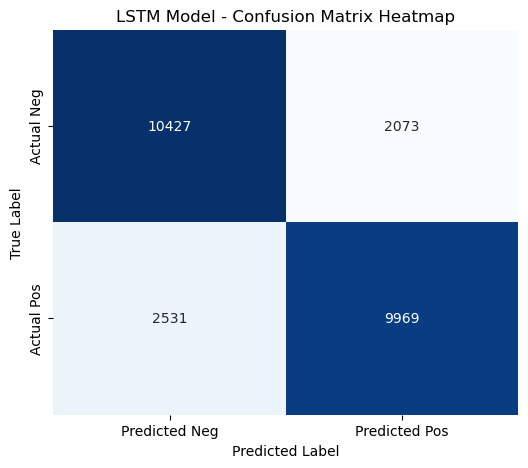

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score

print("--- Step 2: LSTM Confusion Matrix & Detailed Metrics ---")

# 1. Get predictions for all test data using the LSTM model
lstm_test_probs = lstm_model.predict(x_test_padded)
lstm_test_preds = (lstm_test_probs > 0.5).astype(int).flatten()

# 2. Compute the 2x2 Confusion Matrix
cm_lstm = confusion_matrix(y_test, lstm_test_preds)

print("\n[1] Confusion Matrix Breakdown:")
print("=" * 50)
print(f"True Negatives  (Correctly predicted Negative): {cm_lstm[0, 0]}")
print(f"False Positives (Predicted Positive, actually Neg): {cm_lstm[0, 1]}")
print(f"False Negatives (Predicted Negative, actually Pos): {cm_lstm[1, 0]}")
print(f"True Positives  (Correctly predicted Positive): {cm_lstm[1, 1]}")
print("=" * 50)

# 3. Compute individual key metrics using scikit-learn
acc = accuracy_score(y_test, lstm_test_preds)
prec = precision_score(y_test, lstm_test_preds)
rec = recall_score(y_test, lstm_test_preds)
f1 = f1_score(y_test, lstm_test_preds)

print("\n[2] Key Performance Metrics:")
print(f"  • Accuracy  : {acc * 100:.2f}%")
print(f"  • Precision : {prec:.4f} (When LSTM says positive, how often is it right?)")
print(f"  • Recall    : {rec:.4f} (What percentage of actual positives did LSTM find?)")
print(f"  • F1-Score  : {f1:.4f} (The balance between Precision and Recall)")

# 4. Print scikit-learn's full classification report
print("\n[3] Full Classification Report:")
print("-" * 50)
print(classification_report(y_test, lstm_test_preds, target_names=['Negative (0)', 'Positive (1)']))

# 5. Plot a visual heatmap of the confusion matrix for students
plt.figure(figsize=(6, 5))
sns.heatmap(cm_lstm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Neg', 'Predicted Pos'],
            yticklabels=['Actual Neg', 'Actual Pos'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('LSTM Model - Confusion Matrix Heatmap')
plt.show()

## RNN and LSTM Cmparision


In [21]:
import numpy as np

print("--- Step A: Side-by-Side Predictions on 7 Test Samples ---")

# 1. Get predictions for both models on the first 7 test samples
rnn_sample_probs = rnn_model.predict(x_test_padded[:7])
rnn_sample_preds = (rnn_sample_probs > 0.5).astype(int).flatten()

lstm_sample_probs = lstm_model.predict(x_test_padded[:7])
lstm_sample_preds = (lstm_sample_probs > 0.5).astype(int).flatten()

# 2. Re-fetch word index to decode review text snippets
word_index = imdb.get_word_index()
reverse_word_index = {v + 3: k for k, v in word_index.items()}
reverse_word_index[0] = '<PAD>'
reverse_word_index[1] = '<START>'
reverse_word_index[2] = '<UNK>'

# 3. Print side-by-side comparison table for the 7 samples
for i in range(7):
    review_snippet = ' '.join([reverse_word_index.get(idx, '?') for idx in x_test_padded[i][:20]])
    true_label = y_test[i]
    
    rnn_status = "Correct ✅" if true_label == rnn_sample_preds[i] else "Incorrect ❌"
    lstm_status = "Correct ✅" if true_label == lstm_sample_preds[i] else "Incorrect ❌"
    
    print(f"\nTest Sample #{i+1}:")
    print(f"  Preview: {review_snippet}...")
    print(f"  True Label    : {true_label} (1=Positive, 0=Negative)")
    print(f"  SimpleRNN     : Pred Prob = {rnn_sample_probs[i][0]:.4f} | Class = {rnn_sample_preds[i]} [{rnn_status}]")
    print(f"  LSTM          : Pred Prob = {lstm_sample_probs[i][0]:.4f} | Class = {lstm_sample_preds[i]} [{lstm_status}]")
    print("-" * 65)

--- Step A: Side-by-Side Predictions on 7 Test Samples ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 229ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step

Test Sample #1:
  Preview: <START> please give this one a miss br br <UNK> <UNK> and the rest of the cast rendered terrible performances...
  True Label    : 0 (1=Positive, 0=Negative)
  SimpleRNN     : Pred Prob = 0.5337 | Class = 1 [Incorrect ❌]
  LSTM          : Pred Prob = 0.0415 | Class = 0 [Correct ✅]
-----------------------------------------------------------------

Test Sample #2:
  Preview: <START> this film requires a lot of patience because it focuses on mood and character development the plot is very...
  True Label    : 1 (1=Positive, 0=Negative)
  SimpleRNN     : Pred Prob = 0.5554 | Class = 1 [Correct ✅]
  LSTM          : Pred Prob = 0.9743 | Class = 1 [Correct ✅]
-----------------------------------------------------------------

Test Sample #3:
  Preview: <START> many animation buffs consider <UNK> <UNK> the great forgotten genius of o

## Full test samples and report
RNN and LSTM


In [22]:
import numpy as np
from sklearn.metrics import confusion_matrix

print("--- Step B: Full Test Set Confusion Matrices ---\n")

# 1. Ensure all test predictions are computed
rnn_all_probs = rnn_model.predict(x_test_padded)
rnn_all_preds = (rnn_all_probs > 0.5).astype(int).flatten()

lstm_all_probs = lstm_model.predict(x_test_padded)
lstm_all_preds = (lstm_all_probs > 0.5).astype(int).flatten()

# 2. Compute confusion matrices
cm_rnn = confusion_matrix(y_test, rnn_all_preds)
cm_lstm = confusion_matrix(y_test, lstm_all_preds)

# 3. Print SimpleRNN Confusion Matrix
print("=" * 55)
print("SIMPLE RNN CONFUSION MATRIX (All Test Cases):")
print("=" * 55)
print(f"True Negatives  (Correct Neg): {cm_rnn[0, 0]}")
print(f"False Positives (Pred Pos, Act Neg): {cm_rnn[0, 1]}")
print(f"False Negatives (Pred Neg, Act Pos): {cm_rnn[1, 0]}")
print(f"True Positives  (Correct Pos): {cm_rnn[1, 1]}")

# 4. Print LSTM Confusion Matrix
print("\n" + "=" * 55)
print("LSTM CONFUSION MATRIX (All Test Cases):")
print("=" * 55)
print(f"True Negatives  (Correct Neg): {cm_lstm[0, 0]}")
print(f"False Positives (Pred Pos, Act Neg): {cm_lstm[0, 1]}")
print(f"False Negatives (Pred Neg, Act Pos): {cm_lstm[1, 0]}")
print(f"True Positives  (Correct Pos): {cm_lstm[1, 1]}")
print("=" * 55)

--- Step B: Full Test Set Confusion Matrices ---

782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step
SIMPLE RNN CONFUSION MATRIX (All Test Cases):
True Negatives  (Correct Neg): 5871
False Positives (Pred Pos, Act Neg): 6629
False Negatives (Pred Neg, Act Pos): 5744
True Positives  (Correct Pos): 6756

LSTM CONFUSION MATRIX (All Test Cases):
True Negatives  (Correct Neg): 10427
False Positives (Pred Pos, Act Neg): 2073
False Negatives (Pred Neg, Act Pos): 2531
True Positives  (Correct Pos): 9969


In [23]:
from sklearn.metrics import accuracy_score

print("--- Step C: Final Accuracy Score Comparison ---")

# 1. Calculate overall accuracy scores for both models
rnn_accuracy = accuracy_score(y_test, rnn_all_preds)
lstm_accuracy = accuracy_score(y_test, lstm_all_preds)

# 2. Print the results clearly
print("=" * 50)
print(f"SimpleRNN Test Accuracy : {rnn_accuracy * 100:.2f}%")
print(f"LSTM Test Accuracy      : {lstm_accuracy * 100:.2f}%")
print("=" * 50)

# 3. Calculate absolute improvement
improvement = (lstm_accuracy - rnn_accuracy) * 100
print(f"\n💡 Classroom Takeaway: The LSTM outperforms the SimpleRNN")
print(f"   by an incredible +{improvement:.2f}% absolute accuracy on test data!")

--- Step C: Final Accuracy Score Comparison ---
SimpleRNN Test Accuracy : 50.51%
LSTM Test Accuracy      : 81.58%

💡 Classroom Takeaway: The LSTM outperforms the SimpleRNN
   by an incredible +31.08% absolute accuracy on test data!
